<a href="https://colab.research.google.com/github/student-uzma/CSL701-CS10_Machine-Learning-Lab/blob/main/ML_Experiment_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 9
Student Name : Uzma Moh.Rafiq Choudhary

Batch : CS1


Roll Number : CS10



### **Aim**

To implement Classification and Regression Trees (CART) using Python on the Palmer Penguins Dataset Extended.

## Objectives

1. To understand the concept and working of the CART algorithm.
2. To implement Decision Tree Classification using Python.   
3. To visualize the constructed Decision Tree structure and decision boundaries.   
4. To analyze impurity measures such as Gini Index and Entropy.
5. To compare the decision boundary of a Decision Tree with a linear classification boundary (e.g., Logistic Regression).   
6. To evaluate and compare the performance of both classifiers.

# Relevant Theory

###Classification and Regression Trees (CART)
CART is a non-parametric supervised machine learning algorithm used for both classification and regression tasks. It builds a binary decision tree by recursively splitting the dataset based on feature values that maximize information gain or minimize impurity.

A tree consists of:

* Root Node: The topmost node representing the entire dataset.

* Internal Nodes: Decision points based on feature splits.

* Leaf/Terminal Nodes: Output class labels or predictions.

Impurity MeasuresGini Index (Gini Impurity): Measures the frequency with which a randomly chosen element from the set would be incorrectly labeled.$$Gini(D) = 1 - \sum_{i=1}^{k} p_i^2$$where $p_i$ is the probability of an item belonging to class $i$.Entropy & Information Gain: Measures the amount of impurity or randomness in the data.$$Entropy(D) = -\sum_{i=1}^{k} p_i \log_2(p_i)$$Dataset InformationGet the Palmer Penguins Dataset Extended from Kaggle using the following link:https://www.kaggle.com/datasets/samybaladram/palmers-penguin-dataset-extended The Palmer Penguins dataset contains measurements of penguin species across islands in the Palmer Archipelago:AdelieChinstrapGentooThe primary numerical features are:culmen_length_mm (or bill_length_mm)culmen_depth_mm (or bill_depth_mm)flipper_length_mmbody_mass_gFor visualization, we will use: culmen_length_mm and flipper_length_mm.

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Palmer Penguins Extended dataset.
---

In [3]:
# ---------- Task 1: Import Libraries and Load Dataset ----------

# 1. Import libraries
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)

# 2. Upload the zip file (Colab). Select your archive zip in the dialog.
from google.colab import files
uploaded = files.upload()

# 3. Extract the zip
zip_name = list(uploaded.keys())[0]
with zipfile.ZipFile(zip_name) as z:
    z.extractall('.')
print("Files available:", os.listdir('.'))

# 4. Load the dataset
df = pd.read_csv('palmerpenguins_extended.csv')

# 5. Inspect the dataset
print("Shape:", df.shape)
print("\nColumns:", list(df.columns))
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isnull().sum())
print("\nSpecies counts:\n", df['species'].value_counts())
df.head()

Saving archive (13).zip to archive (13) (1).zip
Files available: ['.config', 'archive (13) (1).zip', 'palmerpenguins_extended.csv', 'archive (13).zip', 'palmerpenguins_original.csv', 'sample_data']
Shape: (3430, 11)

Columns: ['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex', 'diet', 'life_stage', 'health_metrics', 'year']

Data types:
 species               object
island                object
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                   object
diet                  object
life_stage            object
health_metrics        object
year                   int64
dtype: object

Missing values:
 species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
diet                 0
life_stage           0
health_metrics       0
year                 0
dtype: i

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,diet,life_stage,health_metrics,year
0,Adelie,Biscoe,53.4,17.8,219.0,5687.0,female,fish,adult,overweight,2021
1,Adelie,Biscoe,49.3,18.1,245.0,6811.0,female,fish,adult,overweight,2021
2,Adelie,Biscoe,55.7,16.6,226.0,5388.0,female,fish,adult,overweight,2021
3,Adelie,Biscoe,38.0,15.6,221.0,6262.0,female,fish,adult,overweight,2021
4,Adelie,Biscoe,60.7,17.9,177.0,4811.0,female,fish,juvenile,overweight,2021


# Task 2: Select Features and Target & Preprocess

* Handle missing values (e.g., drop rows with missing values or impute with median).   
* Select features ($X$) such as culmen_length_mm, culmen_depth_mm, flipper_length_mm, body_mass_g and set species as the target label ($y$).   
* Encode categorical targets if necessary using LabelEncoder.

In [4]:
# ---------- Task 2: Select Features and Target & Preprocess ----------

# 1. Check missing values
print("Missing values before cleaning:\n", df.isnull().sum())

# 2. Handle missing values (drop rows; none are missing in this dataset)
df = df.dropna()
print("\nShape after dropping missing values:", df.shape)

# 3. Select features (X) and target (y)
features = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
X = df[features]
target = df['species']

# 4. Encode the categorical target using LabelEncoder
le = LabelEncoder()
y = le.fit_transform(target)

# 5. Verify
print("\nFeatures used:", features)
print("Classes:", le.classes_)
print("Encoding mapping:", dict(zip(le.classes_, le.transform(le.classes_))))
print("\nX shape:", X.shape)
print("y shape:", y.shape)
X.head()

Missing values before cleaning:
 species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  0
diet                 0
life_stage           0
health_metrics       0
year                 0
dtype: int64

Shape after dropping missing values: (3430, 11)

Features used: ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
Classes: ['Adelie' 'Chinstrap' 'Gentoo']
Encoding mapping: {'Adelie': np.int64(0), 'Chinstrap': np.int64(1), 'Gentoo': np.int64(2)}

X shape: (3430, 4)
y shape: (3430,)


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,53.4,17.8,219.0,5687.0
1,49.3,18.1,245.0,6811.0
2,55.7,16.6,226.0,5388.0
3,38.0,15.6,221.0,6262.0
4,60.7,17.9,177.0,4811.0


# Task 3: Split the Data

* Divide the dataset into training and testing sets using train_test_split.

In [5]:
# ---------- Task 3: Split the Data ----------

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,        # 80% training, 20% testing
    random_state=42,      # reproducible split
    stratify=y            # keep species proportions equal in both sets
)

print("Training set:", X_train.shape, y_train.shape)
print("Testing set :", X_test.shape, y_test.shape)

print("\nTraining class distribution:")
print(pd.Series(le.inverse_transform(y_train)).value_counts())

print("\nTesting class distribution:")
print(pd.Series(le.inverse_transform(y_test)).value_counts())

Training set: (2744, 4) (2744,)
Testing set : (686, 4) (686,)

Training class distribution:
Adelie       1248
Gentoo        998
Chinstrap     498
Name: count, dtype: int64

Testing class distribution:
Adelie       312
Gentoo       249
Chinstrap    125
Name: count, dtype: int64


# Task 4: Implement CART Classifier

* Create a DecisionTreeClassifier model using the Gini criterion (or Entropy).   
* Fit the model on the training data and make predictions on the test set.   

In [6]:
# ---------- Task 4: Implement CART Classifier ----------

# 1. Create the CART model with the Gini criterion
cart = DecisionTreeClassifier(
    criterion='gini',
    max_depth=4,          # limits tree size so it stays readable and avoids overfitting
    random_state=42
)

# 2. Fit on the training data
cart.fit(X_train, y_train)

# 3. Predict on the test set
y_pred = cart.predict(X_test)

print("Model trained successfully")
print("Tree depth       :", cart.get_depth())
print("Number of leaves :", cart.get_n_leaves())
print("First 10 predictions :", le.inverse_transform(y_pred[:10]))
print("First 10 actual      :", le.inverse_transform(y_test[:10]))

# 4. Feature importance
importance = pd.Series(cart.feature_importances_, index=features).sort_values(ascending=False)
print("\nFeature importances:\n", importance)

# 5. Impurity measures: compare Gini vs Entropy
entropy_tree = DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)
entropy_tree.fit(X_train, y_train)

print("\nGini Accuracy    :", round(accuracy_score(y_test, y_pred), 4))
print("Entropy Accuracy :", round(accuracy_score(y_test, entropy_tree.predict(X_test)), 4))

Model trained successfully
Tree depth       : 4
Number of leaves : 16
First 10 predictions : ['Gentoo' 'Gentoo' 'Gentoo' 'Adelie' 'Gentoo' 'Gentoo' 'Adelie' 'Adelie'
 'Gentoo' 'Adelie']
First 10 actual      : ['Adelie' 'Gentoo' 'Adelie' 'Adelie' 'Adelie' 'Gentoo' 'Chinstrap'
 'Adelie' 'Gentoo' 'Adelie']

Feature importances:
 bill_depth_mm        0.543016
body_mass_g          0.272205
bill_length_mm       0.180770
flipper_length_mm    0.004009
dtype: float64

Gini Accuracy    : 0.5671
Entropy Accuracy : 0.5627


# Task 5: Evaluate CART Model

* Accuracy: Calculate classification accuracy.   
* Confusion Matrix: Generate the matrix to analyze misclassifications across species.
* Classification Report: Output Precision, Recall, F1-Score, and Support.   

Accuracy: 0.5671

Confusion Matrix:
 [[209   2 101]
 [ 66   3  56]
 [ 68   4 177]]


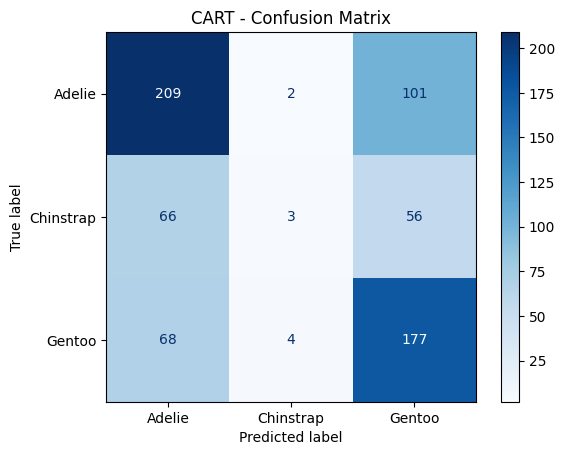


Classification Report:

              precision    recall  f1-score   support

      Adelie       0.61      0.67      0.64       312
   Chinstrap       0.33      0.02      0.04       125
      Gentoo       0.53      0.71      0.61       249

    accuracy                           0.57       686
   macro avg       0.49      0.47      0.43       686
weighted avg       0.53      0.57      0.52       686



In [7]:
# ---------- Task 5: Evaluate CART Model ----------

# 1. Accuracy
acc = accuracy_score(y_test, y_pred)
print("Accuracy:", round(acc, 4))

# 2. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:\n", cm)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(cmap='Blues')
plt.title("CART - Confusion Matrix")
plt.show()

# 3. Classification Report (Precision, Recall, F1-Score, Support)
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=le.classes_, zero_division=0))

# Task 6: Visualize Decision Tree & Decision Boundary

* Visualize Tree Structure: Plot the decision tree diagram using sklearn.tree.plot_tree.
* Select 2-D Features: Select culmen_length_mm and flipper_length_mm.   
* Train 2-D Model & Plot Boundary: Train the decision tree on 2D data and plot axis-aligned rectangular decision boundaries along with data points


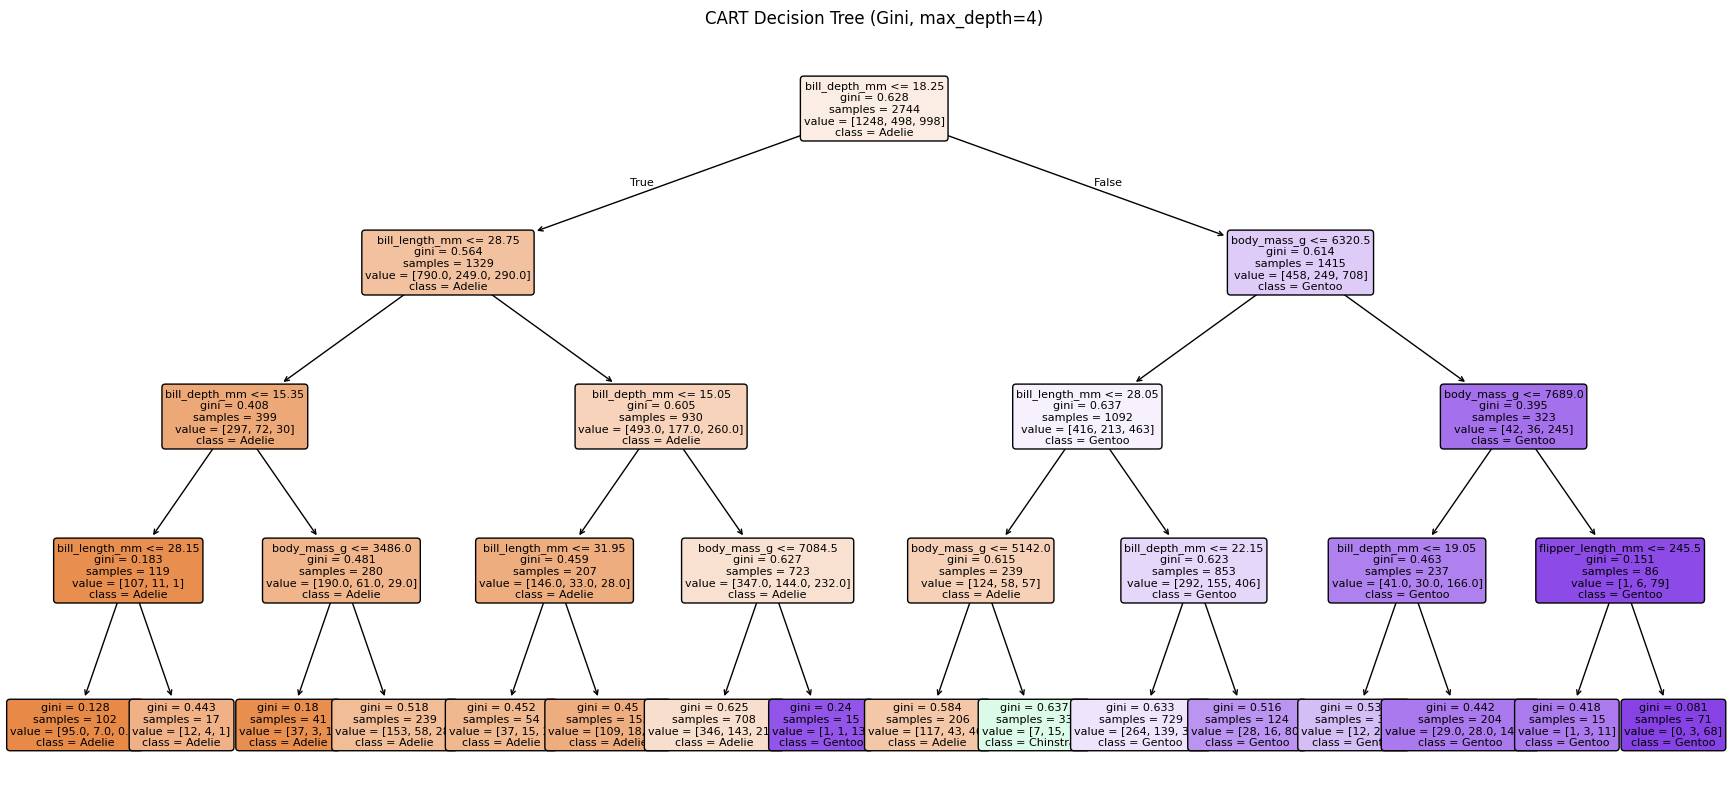

2-D training shape: (2744, 2)
2-D testing shape : (686, 2)
2-D CART accuracy: 0.5131


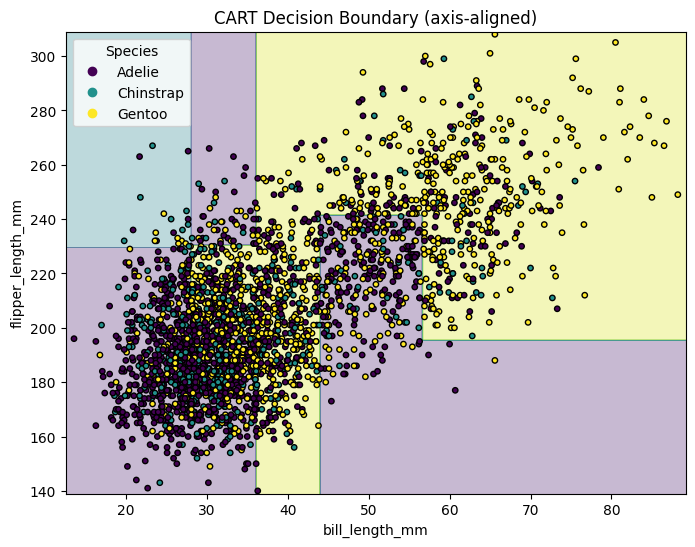

In [8]:
# ---------- Task 6: Visualize Decision Tree & Decision Boundary ----------

# ===== Part A: Visualize Tree Structure =====
plt.figure(figsize=(22, 10))
plot_tree(
    cart,
    feature_names=features,
    class_names=le.classes_,
    filled=True,
    rounded=True,
    fontsize=8
)
plt.title("CART Decision Tree (Gini, max_depth=4)")
plt.show()

# ===== Part B: Select 2-D Features =====
f2 = ['bill_length_mm', 'flipper_length_mm']     # culmen_length_mm = bill_length_mm in this dataset
X2 = df[f2].values

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y, test_size=0.2, random_state=42, stratify=y
)
print("2-D training shape:", X2_train.shape)
print("2-D testing shape :", X2_test.shape)

# ===== Part C: Train 2-D Model =====
cart2 = DecisionTreeClassifier(criterion='gini', max_depth=4, random_state=42)
cart2.fit(X2_train, y2_train)
print("2-D CART accuracy:", round(accuracy_score(y2_test, cart2.predict(X2_test)), 4))

# ===== Part D: Plot Decision Boundary =====
def plot_boundary(model, X, y, ax, title):
    xx, yy = np.meshgrid(
        np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 400),
        np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 400)
    )
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap='viridis')
    scatter = ax.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis', edgecolor='k', s=15)
    ax.set_xlabel(f2[0])
    ax.set_ylabel(f2[1])
    ax.set_title(title)
    handles, _ = scatter.legend_elements()
    ax.legend(handles, le.classes_, title="Species")

fig, ax = plt.subplots(figsize=(8, 6))
plot_boundary(cart2, X2_train, y2_train, ax, "CART Decision Boundary (axis-aligned)")
plt.show()

# Task 7: Normal Linear Classification Boundary

* Train a Logistic Regression model using the same two features as a normal linear baseline.   
* Visualize its linear decision boundary.

Logistic Regression accuracy (2-D): 0.5262


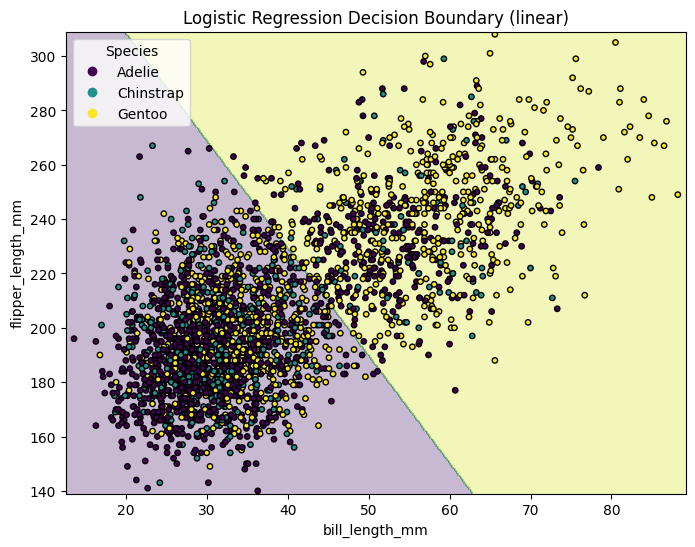

In [9]:
# ---------- Task 7: Normal Linear Classification Boundary ----------

# 1. Train Logistic Regression on the same two features
#    (StandardScaler helps the solver converge; the boundary stays linear)
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
logreg.fit(X2_train, y2_train)

# 2. Quick accuracy check
y2_pred_lr = logreg.predict(X2_test)
print("Logistic Regression accuracy (2-D):", round(accuracy_score(y2_test, y2_pred_lr), 4))

# 3. Visualize the linear decision boundary
fig, ax = plt.subplots(figsize=(8, 6))
plot_boundary(logreg, X2_train, y2_train, ax, "Logistic Regression Decision Boundary (linear)")
plt.show()

# Task 8: Compare CART and Normal Linear Boundary

* Plot both the Decision Tree (axis-aligned non-linear) and Logistic Regression (linear) decision boundaries on side-by-side subplots.   * Compare how non-linear CART boundaries differ from straight linear hyperplanes.

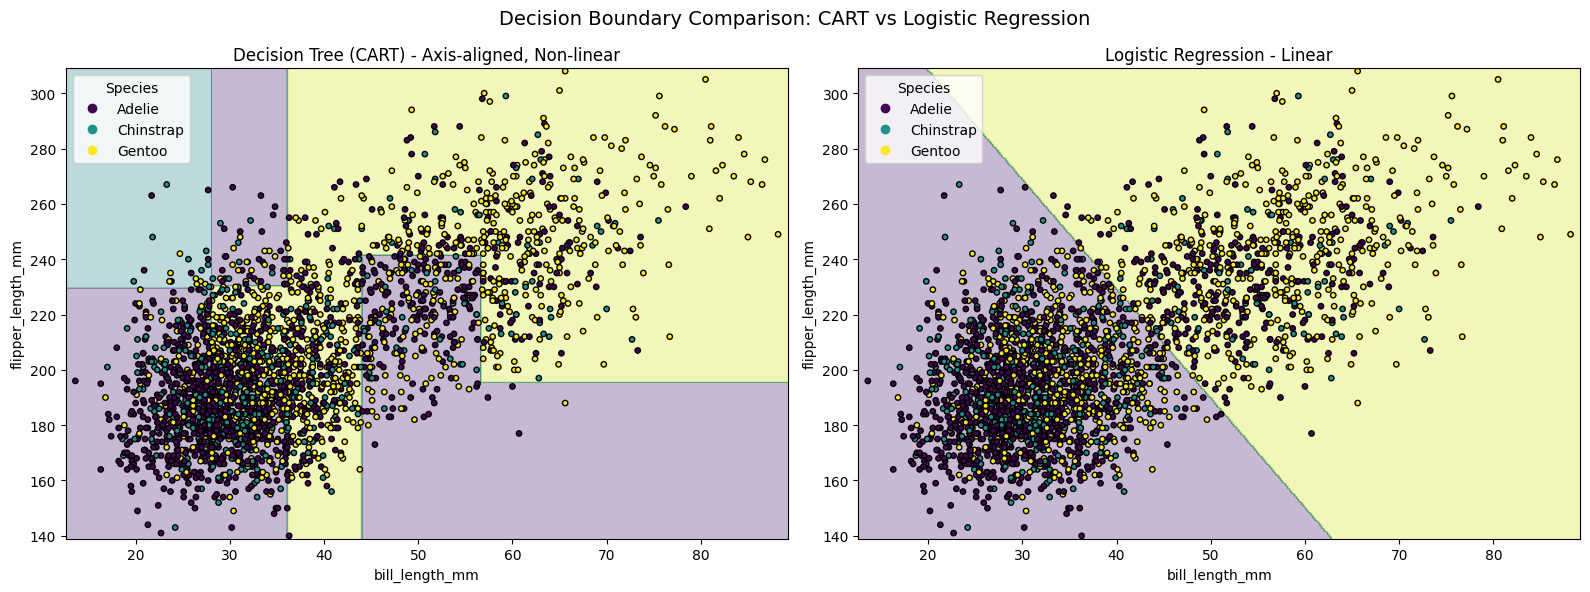

In [10]:
# ---------- Task 8: Compare CART and Normal Linear Boundary ----------

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

plot_boundary(cart2,  X2_train, y2_train, axes[0], "Decision Tree (CART) - Axis-aligned, Non-linear")
plot_boundary(logreg, X2_train, y2_train, axes[1], "Logistic Regression - Linear")

plt.suptitle("Decision Boundary Comparison: CART vs Logistic Regression", fontsize=14)
plt.tight_layout()
plt.show()

# Task 9: Compare Performance

* Compare the evaluation metrics (Accuracy, Confusion Matrix, Classification Report) of the CART Classifier vs. Logistic Regression.

CART (Decision Tree)
Accuracy: 0.5131

Confusion Matrix:
 [[192   1 119]
 [ 77   1  47]
 [ 89   1 159]]

Classification Report:

              precision    recall  f1-score   support

      Adelie       0.54      0.62      0.57       312
   Chinstrap       0.33      0.01      0.02       125
      Gentoo       0.49      0.64      0.55       249

    accuracy                           0.51       686
   macro avg       0.45      0.42      0.38       686
weighted avg       0.48      0.51      0.46       686

Logistic Regression
Accuracy: 0.5262

Confusion Matrix:
 [[245   0  67]
 [102   0  23]
 [133   0 116]]

Classification Report:

              precision    recall  f1-score   support

      Adelie       0.51      0.79      0.62       312
   Chinstrap       0.00      0.00      0.00       125
      Gentoo       0.56      0.47      0.51       249

    accuracy                           0.53       686
   macro avg       0.36      0.42      0.38       686
weighted avg       0.44      0.53   

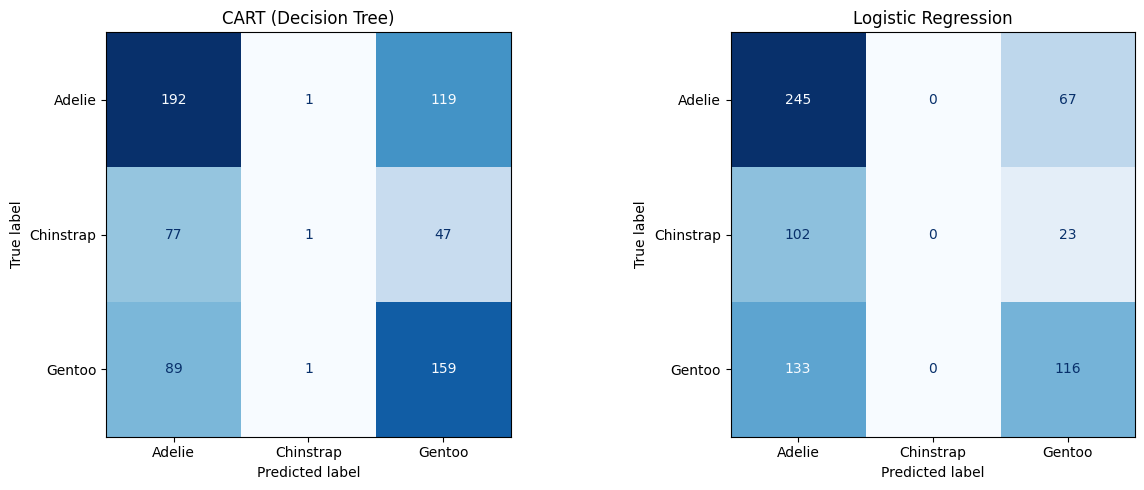


Summary:

               Model  Accuracy  Macro Precision  Macro Recall  Macro F1
CART (Decision Tree)    0.5131           0.4530        0.4206    0.3809
 Logistic Regression    0.5262           0.3578        0.4170    0.3762


In [11]:
# ---------- Task 9: Compare Performance ----------

# 1. Predictions of both models (same 2-D features, same test set)
pred_cart = cart2.predict(X2_test)
pred_lr   = logreg.predict(X2_test)

models = {"CART (Decision Tree)": pred_cart, "Logistic Regression": pred_lr}

# 2. Accuracy, Confusion Matrix, Classification Report for each model
for name, pred in models.items():
    print("=" * 60)
    print(name)
    print("=" * 60)
    print("Accuracy:", round(accuracy_score(y2_test, pred), 4))
    print("\nConfusion Matrix:\n", confusion_matrix(y2_test, pred))
    print("\nClassification Report:\n")
    print(classification_report(y2_test, pred, target_names=le.classes_, zero_division=0))

# 3. Side-by-side confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, pred) in zip(axes, models.items()):
    ConfusionMatrixDisplay(confusion_matrix(y2_test, pred),
                           display_labels=le.classes_).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

# 4. Summary comparison table
from sklearn.metrics import precision_recall_fscore_support
rows = []
for name, pred in models.items():
    p, r, f, _ = precision_recall_fscore_support(y2_test, pred, average='macro', zero_division=0)
    rows.append([name, accuracy_score(y2_test, pred), p, r, f])

summary = pd.DataFrame(rows, columns=["Model", "Accuracy", "Macro Precision", "Macro Recall", "Macro F1"])
print("\nSummary:\n")
print(summary.round(4).to_string(index=False))

# Conclusion

The experiment successfully demonstrated the implementation of the Classification and Regression Tree (CART) algorithm using the Palmer Penguins Extended dataset. The dataset was preprocessed to handle missing values before training. The decision tree structure was visualized, showcasing the hierarchical splits based on feature thresholds. A comparison with a normal linear boundary (Logistic Regression) highlighted CART's ability to create non-linear, axis-aligned decision boundaries to separate different penguin species.